# Metis-Auto: Exploratory Data Analysis of the Sample Chatbot Dataset

**Project:** Intelligent LLM Routing Middleware ("Virtual Meta-Model", *Metis-Auto*)
**Data:** `data.json` - 100 anonymised chatbot sessions (907 messages), Jan-Sep 2026
**Goal of this notebook:** understand what the data *can* and *cannot* support for the three Metis actions
(smart classifier + routing, semantic cache + cascade/failover, cost/observability), and list the work that
must be done before and during the build.

### How to read this notebook
* **Part A - Core EDA:** structure, models, lengths, language, duplicates, latency.
* **Part B - Extended EDA (routing-oriented):** data quality, system prompts, intent buckets, model tiers,
  semantic-cache potential, token/cost scenario, evaluation feasibility.
* **Part C - Findings, gap analysis, pre-work and recommendation.**
* **Part D - Hand-off prompt** for continuing the work with another assistant.

Every claim in the markdown is backed by the cell output right above it. All plots use English labels only
(Persian text is kept in tables, not in figures).

> **Run it yourself:** put `data.json` next to this notebook, then *Run All*.
> Needs: `pandas numpy matplotlib scikit-learn`.

## 0. Setup

In [1]:
import json, re, collections, hashlib, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import TfidfVectorizer

warnings.filterwarnings("ignore")
pd.set_option("display.max_colwidth", 90)
pd.set_option("display.width", 170)
pd.set_option("display.max_columns", 40)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": .25, "figure.figsize": (8, 4)})

DATA_PATH = "data.json"          # <- change if the file lives elsewhere
CAT_SHORT = {"developer_pegahdev": "developer", "general_athena": "general",
             "operator_gapify": "operator", "other_other": "other"}
CAT_COLORS = {"developer": "#4C78A8", "general": "#F58518", "operator": "#54A24B", "other": "#B279A2"}
CPT = 3.0   # ASSUMPTION: characters per token for Persian-heavy text (English is ~4). Used only for rough token estimates.

## 1. Load and flatten
The JSON is a list of 4 blocks (one per usage category), each with 25 sessions, each with an ordered list of messages.
We flatten it into two tables: `S` (one row per session) and `M` (one row per message).

> The brief says the four categories are *intentionally unnamed* so solutions generalise. The JSON nevertheless carries
> names. We keep short labels (`developer / general / operator / other`) **only for analysis and plots**; they must not become model features.

In [2]:
raw = json.load(open(DATA_PATH, encoding="utf-8"))
srows, mrows = [], []
for blk in raw:
    cat = CAT_SHORT[blk["category"]]
    for s in blk["sessions"]:
        srows.append(dict(cat=cat, session_id=s["session_id"], created_at=pd.to_datetime(s["created_at"]),
                          session_len=s["session_len"], user_turns=s["user_turns"], bot_turns=s["bot_turns"]))
        for i, m in enumerate(s["messages"]):
            mrows.append(dict(cat=cat, session_id=s["session_id"], idx=i, role=m["role"], content=m["content"],
                              ts=pd.to_datetime(m["timestamp"]), model=m.get("model"), provider=m.get("provider"),
                              instructions=m.get("instructions"), rag=m.get("rag"), input=m.get("input"),
                              attachments=m.get("attachments")))
S = pd.DataFrame(srows)
M = pd.DataFrame(mrows).sort_values(["session_id", "idx"]).reset_index(drop=True)

# ---- basic per-message features
def script_counts(t):
    return len(re.findall(r"[؀-ۿ]", t)), len(re.findall(r"[A-Za-z]", t))
def lang_of(t):
    fa, en = script_counts(t)
    if fa + en == 0: return "none"
    return "fa" if fa >= en else "en"

M["chars"] = M.content.str.len()
M["words"] = M.content.str.split().str.len()
M["lang"] = M.content.map(lang_of)
M["has_rag"] = M.rag.notna()
M["has_input"] = M.input.notna()
M["has_attach"] = M.attachments.notna()
M["rag_chars"] = M.rag.map(lambda r: len(json.dumps(r, ensure_ascii=False)) if r is not None else 0)
M["instr_chars"] = M.instructions.fillna("").str.len()

# ---- session-level context: the previous user text, conversation size so far, session system prompt
prev_user, hist = [], []
for sid, g in M.groupby("session_id", sort=False):
    last_u, cum = None, 0
    for r in g.itertuples():
        prev_user.append(last_u); hist.append(cum)
        if r.role == "user": last_u = r.content
        cum += r.chars
M["prev_user_text"] = prev_user
M["hist_chars"] = hist           # characters of all earlier messages in the session

sys_of = (M[M.role == "bot"].dropna(subset=["instructions"]).groupby("session_id").instructions.first())
M["sys_hash"] = M.session_id.map(sys_of.map(lambda t: hashlib.md5(t.encode()).hexdigest()[:8]))
M["sys_chars"] = M.session_id.map(sys_of.str.len()).fillna(0)

# ---- who answered?  (LLM vs rule-based workflow vs image model vs unknown)
def source(r):
    if r.role == "user": return "user"
    if r.provider == "workflow": return "workflow (non-LLM)"
    if r.provider == "imagination": return "image model"
    if pd.isna(r.model): return "unknown source"
    return "LLM"
M["source"] = M.apply(source, axis=1)

# ---- ASSUMED model tiers (edit freely). 'strong' = what the brief calls advanced/reasoning models.
STRONG = {"claude-sonnet-4-6", "gpt-5.2", "gpt-5.4", "o3-mini", "gpt-4.1", "deepseek-reasoner"}
def tier(r):
    if r.source != "LLM": return r.source
    return "strong" if r.model in STRONG else "fast/cheap"
M["tier"] = M.apply(tier, axis=1)

U = M[M.role == "user"].copy()
B = M[M.role == "bot"].copy()
LLM = B[B.source == "LLM"].copy()
print("sessions:", len(S), "| messages:", len(M), "| user:", len(U), "| bot:", len(B), "| LLM-generated bot msgs:", len(LLM))
M.head(3)[["cat", "session_id", "role", "content", "model", "provider", "tier"]]

sessions: 100 | messages: 907 | user: 465 | bot: 442 | LLM-generated bot msgs: 377


,cat,session_id,role,content,model,provider,tier
0,operator,sess_00cd4710,user,درود بر شما. لطفا در بخش شبکه‌های اجتماعی ( کانال بله ) را هم اضافه کنید. \nzil.ink/Ly...,NaN,NaN,user
1,operator,sess_00cd4710,bot,درود بر شما! 😊\n\nبرای اضافه کردن کانال بله به بخش شبکه‌های اجتماعی در زیلینک، مراحل ز...,gemini-2.5-flash,google,fast/cheap
2,operator,sess_00cd4710,user,توی شبکه‌های اجتماعی گزینه کانال بله وجود ندارد,NaN,NaN,user


# Part A - Core EDA

## A1. Schema and field availability

In [3]:
avail = pd.DataFrame({
    "user msgs":  [U[c].notna().sum() for c in ["content", "model", "instructions", "rag", "input", "attachments"]],
    "bot msgs":   [B[c].notna().sum() for c in ["content", "model", "instructions", "rag", "input", "attachments"]],
}, index=["content", "model", "instructions (system prompt)", "rag (retrieval)", "input (UI widget)", "attachments"])
display(avail)
print("session keys:", list(S.columns))
chk = M.groupby("session_id").agg(n=("idx", "size"), u=("role", lambda x: (x == "user").sum()), b=("role", lambda x: (x == "bot").sum())).join(S.set_index("session_id"))
print("session_len == #messages :", (chk.n == chk.session_len).mean())
print("user_turns == #user msgs :", (chk.u == chk.user_turns).mean())
print("bot_turns  == #bot msgs  :", (chk.b == chk.bot_turns).mean())

,user msgs,bot msgs
content,465,442
model,0,415
instructions (system prompt),0,415
rag (retrieval),0,71
input (UI widget),0,29
attachments,14,0


session keys: ['cat', 'session_id', 'created_at', 'session_len', 'user_turns', 'bot_turns']
session_len == #messages : 1.0
user_turns == #user msgs : 1.0
bot_turns  == #bot msgs  : 1.0


## A2. Per-category overview

In [4]:
def q(p): return lambda x: x.quantile(p)
ov = pd.DataFrame({
    "sessions": S.groupby("cat").size(),
    "messages": M.groupby("cat").size(),
    "user msgs": U.groupby("cat").size(),
    "bot msgs": B.groupby("cat").size(),
    "session len median": S.groupby("cat").session_len.median(),
    "session len max": S.groupby("cat").session_len.max(),
    "user chars median": U.groupby("cat").chars.median(),
    "user chars p90": U.groupby("cat").chars.quantile(.9),
    "user chars max": U.groupby("cat").chars.max(),
    "bot chars median": B.groupby("cat").chars.median(),
    "bot chars p90": B.groupby("cat").chars.quantile(.9),
})
display(ov.round(1))

,sessions,messages,user msgs,bot msgs,session len median,session len max,user chars median,user chars p90,user chars max,bot chars median,bot chars p90
cat,,,,,,,,,,,
developer,25,183,95,88,6.0,25,40.0,1430.4,4548,201.0,796.2
general,25,266,139,127,6.0,44,35.0,162.2,4666,374.0,1972.0
operator,25,171,86,85,6.0,16,19.0,95.5,292,112.0,837.6
other,25,287,145,142,8.0,30,29.0,137.8,246,204.0,361.4


## A3. Which models answered?
Bot messages carry `model` and `provider`. We split them into **LLM**, **workflow (rule-based, no LLM)**, **image model** and
**unknown source** (no model/provider recorded). Only the LLM rows matter for routing.

source
LLM                   377
workflow (non-LLM)     36
unknown source         27
image model             2 



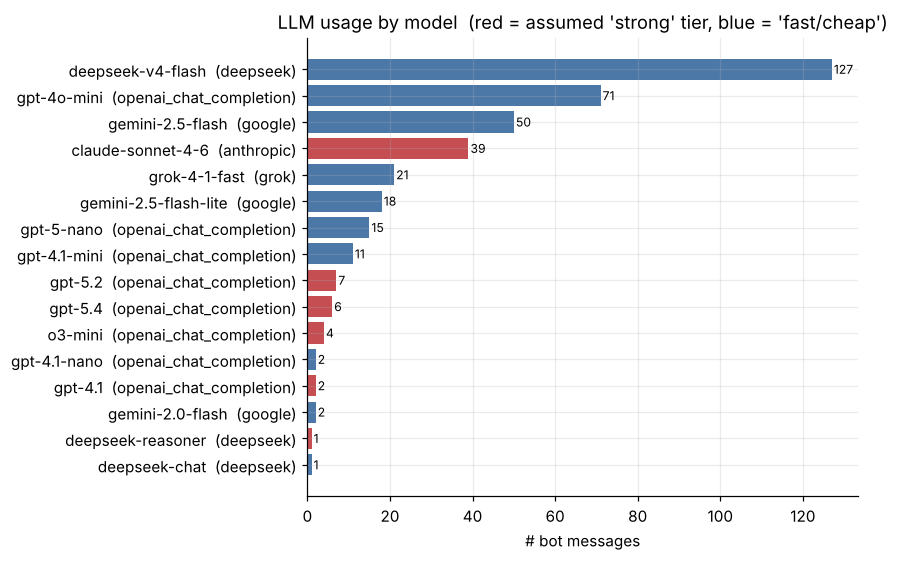

distinct LLM models: 16 | distinct providers (incl. workflow/image): 7


In [5]:
print(B.source.value_counts().to_string(), "\n")
mc = (LLM.groupby(["provider", "model"]).size().sort_values(ascending=True))
tier_of = LLM.drop_duplicates("model").set_index("model").tier
colors = ["#C44E52" if tier_of[m] == "strong" else "#4C78A8" for (_, m) in mc.index]
fig, ax = plt.subplots(figsize=(8, 5.2))
ax.barh([f"{m}  ({p})" for p, m in mc.index], mc.values, color=colors)
ax.set_xlabel("# bot messages"); ax.set_title("LLM usage by model  (red = assumed 'strong' tier, blue = 'fast/cheap')")
for i, v in enumerate(mc.values): ax.text(v + .5, i, str(v), va="center", fontsize=8)
plt.tight_layout(); plt.show()
print("distinct LLM models:", LLM.model.nunique(), "| distinct providers (incl. workflow/image):", B.provider.nunique())

In [6]:
ct = pd.crosstab(LLM.model, LLM.cat)
ct["total"] = ct.sum(axis=1)
display(ct.sort_values("total", ascending=False))

cat,developer,general,operator,other,total
model,,,,,
deepseek-v4-flash,5,0,0,122,127
gpt-4o-mini,3,57,0,11,71
gemini-2.5-flash,0,13,37,0,50
claude-sonnet-4-6,39,0,0,0,39
grok-4-1-fast,1,0,20,0,21
gemini-2.5-flash-lite,0,18,0,0,18
gpt-5-nano,15,0,0,0,15
gpt-4.1-mini,9,2,0,0,11
gpt-5.2,7,0,0,0,7


## A4. Is the model chosen per *query* or per *bot*?
If the dataset were routed per query we would see models change inside a session. We also check whether the system prompt
(`instructions`) changes inside a session.

In [7]:
per_sess_models = LLM.groupby("session_id").model.nunique()
print("sessions with an LLM answer:", len(per_sess_models))
print("sessions using >1 distinct model:", int((per_sess_models > 1).sum()))
per_sess_sys = B.dropna(subset=["instructions"]).groupby("session_id").instructions.nunique()
print("sessions with >1 distinct system prompt:", int((per_sess_sys > 1).sum()))
print("distinct system prompts per category:\n", B.dropna(subset=["instructions"]).groupby("cat").instructions.nunique().to_string())

sessions with an LLM answer: 87
sessions using >1 distinct model: 0
sessions with >1 distinct system prompt: 0
distinct system prompts per category:
 cat
developer    11
general      21
operator     23
other        25


> **Takeaways so far (A1-A4)**
> * The data is clean structurally: session counts and turn counts match the transcripts exactly.
> * 442 bot messages = **377 LLM answers**, 36 rule-based *workflow* answers, 27 with *no recorded source* and 2 image-model answers. Only the 377 LLM answers are routing-relevant. Sixteen distinct LLMs appear (the brief's "18 models" = these 16 + `workflow/default` + `dalle`) across 7 providers.
> * **No session ever switches model or system prompt** (0 of 87 sessions with an LLM answer). The model is therefore a property of *which bot/product was configured*, not a decision made per query. **There is no per-message "correct model" label in this data.**
> * Each category uses a very different model mix (e.g. `other` is 90% `deepseek-v4-flash`, `developer` is the only one using `claude-sonnet-4-6`, `gpt-5.x`). Any "model = f(query)" signal learned from this data would mostly learn *which bot* the query came from.

## A5. User message length

len_bin,<=15,16-100,101-500,>500
cat,,,,
developer,31.6,36.8,15.8,15.8
general,30.2,53.2,12.9,3.6
operator,44.2,46.5,9.3,0.0
other,32.4,52.4,15.2,0.0
ALL,33.8,48.4,13.5,4.3


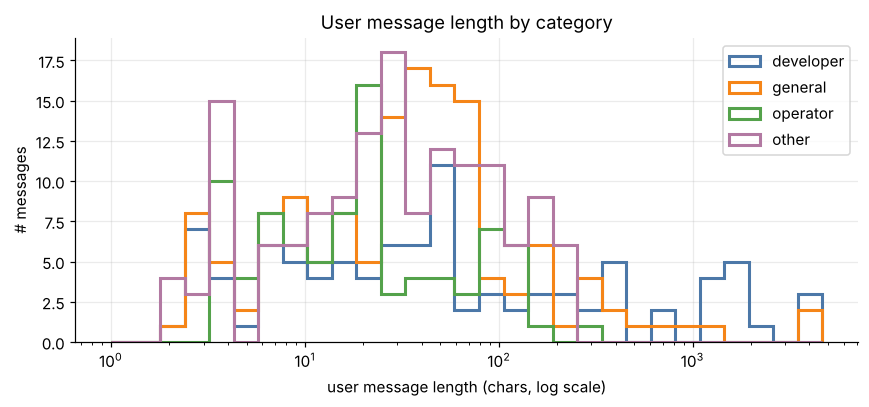

In [8]:
bins = [-1, 15, 100, 500, 10**6]
labels = ["<=15", "16-100", "101-500", ">500"]
U["len_bin"] = pd.cut(U.chars, bins=bins, labels=labels)
share = pd.crosstab(U.cat, U.len_bin, normalize="index").mul(100).round(1)
share.loc["ALL"] = (U.len_bin.value_counts(normalize=True).reindex(labels) * 100).round(1)
display(share)

fig, ax = plt.subplots(figsize=(8, 3.8))
edges = np.logspace(0, np.log10(max(U.chars.max(), 10)), 30)
for c, g in U.groupby("cat"):
    ax.hist(g.chars.clip(lower=1), bins=edges, histtype="step", lw=2, label=c, color=CAT_COLORS[c])
ax.set_xscale("log"); ax.set_xlabel("user message length (chars, log scale)"); ax.set_ylabel("# messages")
ax.set_title("User message length by category"); ax.legend(); plt.tight_layout(); plt.show()

## A6. Language mix (script-based)

In [9]:
lm = pd.crosstab(U.cat, U.lang, normalize="index").mul(100).round(1)
lm.loc["ALL"] = (U.lang.value_counts(normalize=True) * 100).round(1)
display(lm)
mix_bot = pd.crosstab(B.cat, B.lang, normalize="index").mul(100).round(1)
print("Bot-message language mix (%):"); display(mix_bot)

lang,en,fa,none
cat,,,
developer,16.8,83.2,0.0
general,7.2,92.8,0.0
operator,3.5,96.5,0.0
other,1.4,97.2,1.4
ALL,6.7,92.9,0.4


Bot-message language mix (%):


lang,en,fa,none
cat,,,
developer,2.3,94.3,3.4
general,14.2,85.8,0.0
operator,3.5,96.5,0.0
other,0.7,99.3,0.0


## A7. Duplicates and short messages
Exact (normalised) repeats are the cheapest cache wins. Normalisation: lower-case, unify Arabic/Persian *ya/kaf*,
remove diacritics/ZWNJ/punctuation/emoji, collapse spaces.

In [10]:
def norm(t):
    t = t.replace("\\n", " ").replace("ي", "ی").replace("ك", "ک").replace("‌", " ")
    t = re.sub(r"[ً-ٟـ]", "", t)
    t = re.sub(r"[^\w\s]", " ", t.lower())
    return re.sub(r"\s+", " ", t).strip()
U["norm"] = U.content.map(norm)
vc = U.norm.value_counts()
print("user msgs:", len(U), "| unique after normalisation:", U.norm.nunique(),
      "| redundant (repeat) msgs:", len(U) - U.norm.nunique(), f"({(len(U)-U.norm.nunique())/len(U):.1%})")
print("\nMost repeated messages:")
display(vc[vc > 1].head(12).rename("count").to_frame())
dups = U.groupby("cat").apply(lambda g: pd.Series({"msgs": len(g), "unique": g.norm.nunique(), "repeat %": round(100 * (1 - g.norm.nunique() / len(g)), 1)}))
display(dups)

user msgs: 465 | unique after normalisation: 408 | redundant (repeat) msgs: 57 (12.3%)

Most repeated messages:


,count
norm,
سلام,26
خیر,4
جواب بده,4
ممنون,3
الو,3
start,3
سلام وقت بخیر,3
باش,3
عزیزم بازی چطور بود,3


,msgs,unique,repeat %
cat,,,
developer,95.0,87.0,8.4
general,139.0,128.0,7.9
operator,86.0,73.0,15.1
other,145.0,130.0,10.3


## A8. Special inputs: retrieval (RAG), UI widgets, attachments, non-LLM answers

In [11]:
spec = pd.DataFrame({
    "bot msgs": B.groupby("cat").size(),
    "with RAG": B.groupby("cat").has_rag.sum(),
    "workflow (non-LLM)": B[B.source == "workflow (non-LLM)"].groupby("cat").size(),
    "unknown source": B[B.source == "unknown source"].groupby("cat").size(),
    "image model": B[B.source == "image model"].groupby("cat").size(),
    "user msgs with attachment": U.groupby("cat").has_attach.sum(),
    "msgs with UI-widget input": M.groupby("cat").has_input.sum(),
}).fillna(0).astype(int)
spec.loc["ALL"] = spec.sum()
display(spec)
a = M[M.has_attach]
print("attachment content types:", collections.Counter(c["contentType"] for lst in a.attachments for c in lst))
r = M[M.has_rag].iloc[0].rag
print("\nRAG object keys:", list(r.keys()), "| #context passages in first example:", len(r["context"]))
print("RAG context chars (median / max):", int(B[B.has_rag].rag_chars.median()), "/", int(B.rag_chars.max()))

,bot msgs,with RAG,workflow (non-LLM),unknown source,image model,user msgs with attachment,msgs with UI-widget input
cat,,,,,,,
developer,88,31,3,0,0,4,0
general,127,0,0,27,2,10,0
operator,85,38,28,0,0,0,27
other,142,2,5,0,0,0,2
ALL,442,71,36,27,2,14,29


attachment content types: Counter({'IMAGE': 15})

RAG object keys: ['query', 'context'] | #context passages in first example: 5
RAG context chars (median / max): 1578 / 4229


## A9. Response gap (a rough latency proxy)
`gap` = timestamp(next bot message) - timestamp(user message) when a bot message directly follows a user message.
Timestamps have **1-second resolution** and the gap includes queueing/network, so this is only an order-of-magnitude proxy.

In [12]:
M["next_role"] = M.groupby("session_id").role.shift(-1)
M["next_ts"] = M.groupby("session_id").ts.shift(-1)
M["next_tier"] = M.groupby("session_id").tier.shift(-1)
M["next_model"] = M.groupby("session_id").model.shift(-1)
M["next_content"] = M.groupby("session_id").content.shift(-1)
G = M[(M.role == "user") & (M.next_role == "bot")].copy()
G["gap"] = (G.next_ts - G.ts).dt.total_seconds()
print("user->bot pairs:", len(G))
lat = G.groupby("cat").gap.describe(percentiles=[.5, .9]).round(1)[["count", "mean", "50%", "90%", "max"]]
display(lat)
lat_t = G.groupby("next_tier").gap.describe(percentiles=[.5, .9]).round(1)[["count", "mean", "50%", "90%", "max"]]
print("By answering tier:"); display(lat_t)

user->bot pairs: 434


,count,mean,50%,90%,max
cat,,,,,
developer,88.0,6.3,4.0,9.3,72.0
general,123.0,4.4,1.0,12.8,59.0
operator,82.0,1.4,1.0,3.0,8.0
other,141.0,3.2,2.0,3.0,118.0


By answering tier:


,count,mean,50%,90%,max
next_tier,,,,,
fast/cheap,316.0,3.4,2.0,4.0,118.0
strong,59.0,4.0,4.0,7.0,10.0
unknown source,27.0,12.6,10.0,22.4,59.0
workflow (non-LLM),32.0,1.0,0.0,5.0,8.0


> **Takeaways (A5-A9)**
> * **Traffic is short and Persian.** 34% of user messages have <=15 characters, 82% have <=100; only 4% exceed 500 characters (all of them in `developer` and `general`). 93% of user messages are Persian script, 7% English (17% in `developer`).
> * **Repeats are common:** 57 of 465 user messages (12%) are exact repeats after normalisation; the single word *"salam"* alone appears 26 times.
> * **Special inputs are rare but real:** 71 bot messages use retrieval (RAG; only `developer` and `operator`), 14 user messages carry attachments (15 images, no audio), 29 bot messages carry UI-widget input. Code is effectively absent (0 messages detected).
> * **Latency proxy:** median user->bot gap is 1-4 s per category; strong-tier answers take ~2x the cheap tier (median 4 s vs 2 s; p90 7 s vs 4 s). The 27 "unknown source" answers are slow (median 10 s) and are long academic-style texts - probably a different long-form pipeline. Timestamps have 1 s resolution, so use this only as a rough guide.

# Part B - Extended EDA (routing-oriented)

## B1. Data quality audit
Things that will silently break a router or an evaluation if ignored.

In [13]:
issues = {}
# 1) user messages not followed by a bot reply
issues["user msgs with no bot reply directly after"] = int(((M.role == "user") & (M.next_role != "bot")).sum())
# 2) consecutive duplicate user messages (user re-sent)
M["prev_content"] = M.groupby("session_id").content.shift(1)
M["prev_role"] = M.groupby("session_id").role.shift(1)
issues["consecutive identical user msgs"] = int(((M.role == "user") & (M.prev_role == "user") & (M.content == M.prev_content)).sum())
# 3) bot messages with no model/provider that are not workflow
issues["bot msgs with unknown source"] = int((B.source == "unknown source").sum())
# 4) workflow control tags inside bot text
issues["bot text containing '<==...==>' workflow tags"] = int(B.content.str.contains(r"<==.*?==>", regex=True).sum())
# 5) bot text that is a JSON blob
def is_json(t):
    t = t.strip()
    if not t.startswith("{"): return False
    try: json.loads(t); return True
    except Exception: return False
B["json_out"] = B.content.map(is_json)
issues["bot text that is a JSON object"] = int(B.json_out.sum())
# 6) garbled output: stray CJK / Cyrillic / Latin-extended characters inside an otherwise Persian/English reply
odd = re.compile(r"[\u3000-\u9fff\u0400-\u04ff\u0100-\u017f]")
glue = re.compile(r"[\u0600-\u06FF][A-Za-z]|[A-Za-z][\u0600-\u06FF]")
B["garbled"] = B.content.map(lambda t: bool(odd.search(t)))
issues["bot msgs with stray CJK/Cyrillic/Latin-extended chars (garbled)"] = int(B.garbled.sum())
# 7) PII placeholders left by anonymisation
ph = re.compile(r"\[[A-Z_]{3,}\]")
issues["messages containing PII placeholders like [NAME]"] = int(M.content.str.contains(ph).sum())
issues["user msgs that are automatic retry prompts ('previous response was invalid')"] = int(U.content.str.contains("previous response was invalid", case=False).sum())
issues["empty / whitespace-only messages"] = int((M.content.str.strip() == "").sum())
display(pd.Series(issues, name="count").to_frame())
print("Examples of garbled output:")
for r in B[B.garbled].head(3).itertuples(): print(f" - [{r.cat} / {r.model}]", r.content[:150].replace("\n", " "))
print("\nPlaceholder types seen:", collections.Counter(p for t in M.content for p in ph.findall(t)).most_common(8))

,count
user msgs with no bot reply directly after,31
consecutive identical user msgs,5
bot msgs with unknown source,27
bot text containing '<==...==>' workflow tags,11
bot text that is a JSON object,22
bot msgs with stray CJK/Cyrillic/Latin-extended chars (garbled),3
messages containing PII placeholders like [NAME],17
user msgs that are automatic retry prompts ('previous response was invalid'),3
empty / whitespace-only messages,0


Examples of garbled output:
 - [general / gpt-4o-mini] وای! سوال خوبی هست! من خودم خیلی به مراقبت از پوست اهمیت می‌دم. یه روتین ساده اما مؤثر دارم:   1. **تمیز کننده:** همیشه پوستم رو با یه تمیز کننده ملای
 - [other / gpt-4o-mini] سلامم، عزیزم تو هم زحم دلبر مخ genteهseparator نباشی 😘🌹 روز الیخوanimator všet、 parachute!
 - [other / gpt-4o-mini] Tomatoes parazit併 StreDaar parcels polycrystalline magistrate progesterone conversion hordes ------- urgie interconnected subscribing stirred_SE AUTOM

Placeholder types seen: [('[NATIONAL_ID]', 8), ('[COORD]', 4), ('[LANDLINE]', 4), ('[PHONE]', 3), ('[NAME]', 3), ('[ANALYSIS]', 2), ('[ENROLLMENT]', 1), ('[ALLOCATION]', 1)]


> **Takeaways (data quality)**
> * 31 user messages have no bot reply directly after them (user sent several messages in a row, or the bot never answered) -> *turn pairing* must be handled explicitly.
> * 27 bot messages have no model/provider; 36 come from non-LLM workflows; 11 contain UI control tags like `<==...==>`; 22 are raw JSON objects (machine-to-machine traffic from an app, not human chat). These need **cleaning or exclusion** before computing any quality metric.
> * Machine-generated traffic exists: `developer` contains templated prompts ("Rewrite this listing as...", JSON payloads, automatic *"Your previous response was invalid"* retry prompts). That is useful: **output validators (valid JSON, required keys) are a natural trigger for cascade escalation.**
> * Three bot answers are visibly garbled (random foreign words/characters) - **all three from `gpt-4o-mini`**. Reference answers are not ground truth; an LLM-judge is safer than pure similarity.
> * 17 messages contain PII placeholders (`[NATIONAL_ID]`, `[PHONE]`, ...). Keep them as tokens; they carry no information and should not be embedded as meaningful words.

## B2. What actually makes up the model input? (system prompt, retrieval, history)
A routing decision only changes the *price per token*; what matters for cost is *how many tokens* each call carries.
For each LLM call we approximate input = system prompt + retrieved context + conversation so far (which includes the current user message).
Token counts are rough (`chars / CPT`, CPT=3 for Persian-heavy text).

,system prompt %,retrieval %,conversation %
cat,,,
developer,71.5,4.3,24.2
general,26.1,0.0,73.9
operator,56.7,32.9,10.4
other,76.6,0.3,23.2
ALL,58.7,6.6,34.8


,calls,input_tok_mean,input_tok_median,output_tok_mean
cat,,,,
developer,85.0,1944.0,1873.0,109.0
general,98.0,1861.0,753.0,353.0
operator,57.0,1986.0,2042.0,129.0
other,137.0,1648.0,1569.0,119.0
ALL,377.0,1821.0,1660.0,179.0


Overall input:output token ratio (mean) = 10.2 : 1


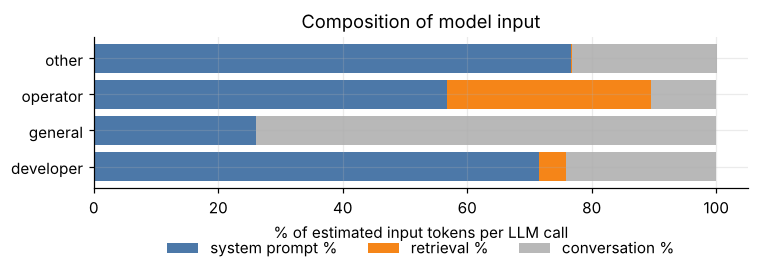

In [14]:
L = LLM.copy()
L["in_sys"] = L.sys_chars / CPT
L["in_rag"] = L.rag_chars / CPT
L["in_hist"] = L.hist_chars / CPT
L["in_total"] = L.in_sys + L.in_rag + L.in_hist
L["out_tok"] = L.chars / CPT
comp = L.groupby("cat")[["in_sys", "in_rag", "in_hist"]].mean()
comp_pct = comp.div(comp.sum(axis=1), axis=0).mul(100).round(1)
tot = L[["in_sys", "in_rag", "in_hist"]].mean(); comp_pct.loc["ALL"] = (tot / tot.sum() * 100).round(1)
comp_pct.columns = ["system prompt %", "retrieval %", "conversation %"]
display(comp_pct)
summ = L.groupby("cat").agg(calls=("idx", "size"), input_tok_mean=("in_total", "mean"), input_tok_median=("in_total", "median"), output_tok_mean=("out_tok", "mean")).round(0)
summ.loc["ALL"] = [len(L), L.in_total.mean().round(0), L.in_total.median().round(0), L.out_tok.mean().round(0)]
display(summ)
print(f"Overall input:output token ratio (mean) = {L.in_total.mean() / L.out_tok.mean():.1f} : 1")

fig, ax = plt.subplots(figsize=(7, 3.2))
cp = comp_pct.drop("ALL")
left = np.zeros(len(cp))
for col, colr in zip(cp.columns, ["#4C78A8", "#F58518", "#B8B8B8"]):
    ax.barh(cp.index, cp[col], left=left, label=col, color=colr); left += cp[col].values
ax.set_xlabel("% of estimated input tokens per LLM call"); ax.set_title("Composition of model input"); ax.legend(loc="lower center", bbox_to_anchor=(.5, -.55), ncol=3, frameon=False)
plt.tight_layout(); plt.show()

> **Takeaways (what the model actually reads)**
> * On average **~59% of the estimated input tokens are the system prompt**, ~35% the conversation, ~7% retrieval (33% in `operator`). Input is **~10x larger than output** (~1,800 vs ~180 tokens per call, rough estimate).
> * Implication 1: cost is driven by the **bot's system prompt and RAG context**, not by the user's short message. A router that only looks at the user message is right to do so for *difficulty*, but the **cost model and the cache key must include the system prompt and context**.
> * Implication 2: besides routing and semantic caching, **provider-side prompt caching and prompt trimming** are likely larger savings levers than the brief mentions. Worth one line in the final report.
> * Caveat: character-to-token ratio (CPT=3) is a guess; replace with real tokenizers before quoting any figure.

## B3. Rule-based intent buckets (EDA only - not the final classifier)
A cheap, transparent labelling to see what kind of traffic a router would face.
Buckets: `greeting/thanks`, `question`, `long (>500 chars)`, `short other (<=15)`, `other`.

bucket,greeting/thanks,long (>500),other,question,short other (<=15)
cat,,,,,
developer,18.9,15.8,42.1,11.6,11.6
general,5.8,3.6,46.8,23.7,20.1
operator,20.9,0.0,37.2,18.6,23.3
other,11.7,0.0,51.0,20.0,17.2
ALL,13.1,4.3,45.4,19.1,18.1


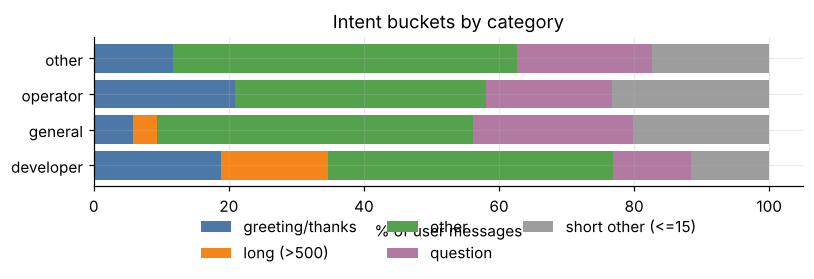

In [15]:
GREET = {"سلام", "درود", "hi", "hello", "hey", "salam", "ممنون", "مرسی", "تشکر", "متشکرم", "سپاس", "خداحافظ", "الو", "باشه", "اوکی", "ok", "okay", "وقت", "بله", "خیر", "نه", "آره"}
QW = {"چی", "چیه", "چطور", "چگونه", "چرا", "کی", "کجا", "آیا", "چند", "کدام", "کدوم", "چه", "how", "what", "why", "when", "where", "which", "can", "could", "is", "are", "do", "does"}
def bucket(raw):
    n = norm(raw); toks = n.split()
    if len(raw) > 500: return "long (>500)"
    if toks and toks[0] in GREET and len(n) <= 20: return "greeting/thanks"
    if "?" in raw or "؟" in raw or (set(toks) & QW): return "question"
    if len(raw) <= 15: return "short other (<=15)"
    return "other"
U["bucket"] = U.content.map(bucket)
bk = pd.crosstab(U.cat, U.bucket, normalize="index").mul(100).round(1)
bk.loc["ALL"] = (U.bucket.value_counts(normalize=True) * 100).round(1)
display(bk)

fig, ax = plt.subplots(figsize=(7.5, 3.4))
bkp = bk.drop("ALL"); left = np.zeros(len(bkp))
pal = ["#4C78A8", "#F58518", "#54A24B", "#B279A2", "#9D9D9D"]
for col, colr in zip(bkp.columns, pal):
    ax.barh(bkp.index, bkp[col], left=left, label=col, color=colr); left += bkp[col].values
ax.set_xlabel("% of user messages"); ax.set_title("Intent buckets by category"); ax.legend(loc="lower center", bbox_to_anchor=(.5, -.6), ncol=3, frameon=False)
plt.tight_layout(); plt.show()

> **Takeaways (intent buckets)**
> * Roughly **13% greetings/thanks, 18% other very short messages, 19% questions, 4% long inputs, 45% "other"** (statements, commands, pasted text). Greetings + very short messages are about a third of traffic and are the obvious "cheap or cached" candidates.
> * `developer` has the most long inputs (16% >500 chars); `operator` has the most greetings (21%) and no long input at all. The mix differs a lot by category -> a threshold tuned on one category will not transfer.
> * These buckets are a transparent EDA aid, not the production classifier.

## B4. Which tier answered which traffic?
**Assumption (editable in the setup cell):** `strong` = `claude-sonnet-4-6, gpt-5.2, gpt-5.4, o3-mini, gpt-4.1, deepseek-reasoner`;
everything else answered by an LLM is `fast/cheap`. This follows the brief's own examples (cheap = flash / mini, advanced = Sonnet / o3-mini).

In [16]:
tshare = pd.crosstab(B.cat, B.tier, normalize="index").mul(100).round(1)
display(tshare)
# the user message that preceded each LLM answer
LL = LLM.copy()
LL["u_chars"] = LL.prev_user_text.fillna("").str.len()
LL["u_bucket"] = LL.prev_user_text.fillna("").map(bucket)
d1 = LL.groupby("tier").agg(n=("idx", "size"), user_chars_median=("u_chars", "median"), user_chars_p90=("u_chars", lambda x: x.quantile(.9)),
                           answer_chars_median=("chars", "median"), with_RAG=("has_rag", "mean"), with_attachment=("has_attach", "mean")).round(2)
display(d1)
print("Strong-tier messages by model and category:")
display(pd.crosstab(LL[LL.tier == "strong"].model, LL[LL.tier == "strong"].cat))
print("Intent bucket of the preceding user message, by tier (% within tier):")
display(pd.crosstab(LL.tier, LL.u_bucket, normalize="index").mul(100).round(1))
print("Strong-tier user messages are the long ones? chars of preceding user msg per strong model:")
display(LL[LL.tier == "strong"].groupby("model").u_chars.describe()[["count", "min", "50%", "max"]])

tier,fast/cheap,image model,strong,unknown source,workflow (non-LLM)
cat,,,,,
developer,37.5,0.0,59.1,0.0,3.4
general,71.7,1.6,5.5,21.3,0.0
operator,67.1,0.0,0.0,0.0,32.9
other,96.5,0.0,0.0,0.0,3.5


,n,user_chars_median,user_chars_p90,answer_chars_median,with_RAG,with_attachment
tier,,,,,,
fast/cheap,318,29.0,145.5,216.5,0.12,0.0
strong,59,45.0,1428.8,148.0,0.47,0.0


Strong-tier messages by model and category:


cat,developer,general
model,,
claude-sonnet-4-6,39,0
deepseek-reasoner,0,1
gpt-4.1,0,2
gpt-5.2,7,0
gpt-5.4,6,0
o3-mini,0,4


Intent bucket of the preceding user message, by tier (% within tier):


u_bucket,greeting/thanks,long (>500),other,question,short other (<=15)
tier,,,,,
fast/cheap,12.9,2.5,44.3,21.4,18.9
strong,20.3,16.9,39.0,18.6,5.1


Strong-tier user messages are the long ones? chars of preceding user msg per strong model:


,count,min,50%,max
model,,,,
claude-sonnet-4-6,39.0,3.0,36.0,393.0
deepseek-reasoner,1.0,4.0,4.0,4.0
gpt-4.1,2.0,29.0,59.0,89.0
gpt-5.2,7.0,791.0,1428.0,1581.0
gpt-5.4,6.0,424.0,2173.5,4548.0
o3-mini,4.0,4.0,8.0,10.0


> **Takeaways (tiers vs traffic)** - tiers are *my assumption* (see setup cell), aligned with the brief's examples.
> * **84% of LLM answers are already on the fast/cheap tier**; only 59 answers (16%) come from 16 sessions on the strong tier. Savings versus *current production* will therefore be much smaller than savings versus "always premium". The report must state which baseline it uses (the brief asks for "single premium-model baseline", so show both).
> * The strong tier is **not** "hard questions": `claude-sonnet-4-6` answered 39 messages with a **median of 36 characters** (RAG-based support replies), `o3-mini` answered messages with a median of 8 characters. Only `gpt-5.2/5.4` correspond to long inputs (424-4,548 chars).
> * So "model used" is a noisy, confounded proxy for difficulty. Do **not** train the router to imitate it.

## B5. Is there a usable "difficulty" signal in the data?
The classifier needs labels like *simple / complex*. We check whether the **tier that answered** could serve as that label,
and which cheap features separate tiers at all.

In [17]:
F = LL[["cat", "model", "tier", "session_id", "u_chars", "hist_chars", "has_rag", "has_attach", "sys_chars", "rag_chars"]].copy()
F["is_strong"] = (F.tier == "strong").astype(int)
F["has_code"] = LL.prev_user_text.fillna("").str.contains(r"```|def |function |import |SELECT |<div|=>|#include|console\.", regex=True).astype(int)
F["has_digits"] = LL.prev_user_text.fillna("").str.contains(r"[0-9۰-۹]", regex=True).astype(int)
F["has_url"] = LL.prev_user_text.fillna("").str.contains(r"https?://|www\.", regex=True).astype(int)
print("strong-tier answers:", int(F.is_strong.sum()), "of", len(F), "LLM answers")
print("strong-tier answers by #distinct sessions:", F[F.is_strong == 1].session_id.nunique(), "sessions")
print("messages with code-like content:", int(F.has_code.sum()), "| URLs:", int(F.has_url.sum()))
print()
display(F.groupby("is_strong")[["u_chars", "hist_chars", "has_rag", "has_attach", "sys_chars", "has_digits"]].median().round(1))

# how much of the 'strong' label is explained by session (bot config) vs by the message?
sess_strong = F.groupby("session_id").is_strong.mean()
print("\nSessions that are 100% strong:", int((sess_strong == 1).sum()), "| 100% cheap:", int((sess_strong == 0).sum()), "| mixed:", int(((sess_strong > 0) & (sess_strong < 1)).sum()))

strong-tier answers: 59 of 377 LLM answers
strong-tier answers by #distinct sessions: 16 sessions
messages with code-like content: 0 | URLs: 7



,u_chars,hist_chars,has_rag,has_attach,sys_chars,has_digits
is_strong,,,,,,
0,29.0,660.5,0.0,0.0,3361.0,0.0
1,45.0,468.0,0.0,0.0,4856.0,0.0



Sessions that are 100% strong: 16 | 100% cheap: 71 | mixed: 0


> **Takeaways (is there a difficulty signal?)**
> * Every session is either 100% strong (16 sessions) or 100% cheap (71) - **no mixed sessions**. The tier is a bot-level setting, so within-bot variation (which is what a router needs) does not exist in the data.
> * With only 59 strong answers from 16 sessions, and zero code-like messages, a classifier trained on `tier` would overfit to bots/sessions. **Conclusion: difficulty labels must be created, not extracted** (see Part C).
> * Cheap features that clearly vary with traffic: message length, intent bucket, language, presence of RAG/attachment, and (not available as label but useful as feature) session history length.

## B6. Semantic-cache potential (a lexical lower bound)
We approximate semantic similarity with **TF-IDF over character 2-4-grams** (language-agnostic, works for Persian, no model download).
For every user message we look at all *earlier* user messages (by timestamp) and take the best cosine similarity. Two scopes:

* **same-bot** - earlier message was sent to a bot with the *same system prompt* (a cache hit is only safe here: the same question to a different bot should get a different answer);
* **any-bot** - ignores the system prompt (unsafe, shown for contrast).

"Non-trivial" excludes greetings/thanks and messages with <=15 characters, which are trivially cacheable but worthless.
Real embeddings (multilingual) will find more paraphrases than this - treat these numbers as a **floor**.

In [18]:
Uc = U.sort_values("ts", kind="stable").reset_index(drop=True)
Uc = Uc[Uc.norm.str.len() > 0].reset_index(drop=True)
vec = TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 4), min_df=1, sublinear_tf=True)
X = vec.fit_transform(Uc.norm)
sim = (X @ X.T).toarray()
n = len(Uc)
earlier = np.tril(np.ones((n, n), dtype=bool), k=-1)
sh = Uc.sys_hash.astype(object).to_numpy()
same_bot = (sh[:, None] == sh[None, :]) & pd.notna(sh)[:, None]
masked_same = np.where(earlier & same_bot, sim, 0)
masked_any = np.where(earlier, sim, 0)
Uc["best_same_bot"] = masked_same.max(1); Uc["arg_same_bot"] = masked_same.argmax(1)
Uc["best_any_bot"] = masked_any.max(1)
Uc["trivial"] = (Uc.bucket == "greeting/thanks") | (Uc.chars <= 15)

ths = [0.95, 0.90, 0.80, 0.70]
rows = []
for th in ths:
    nt = Uc[~Uc.trivial]
    rows.append({"threshold": th,
                 "all msgs | same-bot %": round(100 * (Uc.best_same_bot >= th).mean(), 1),
                 "all msgs | any-bot %": round(100 * (Uc.best_any_bot >= th).mean(), 1),
                 "non-trivial | same-bot %": round(100 * (nt.best_same_bot >= th).mean(), 1),
                 "non-trivial | any-bot %": round(100 * (nt.best_any_bot >= th).mean(), 1)})
print(f"user msgs analysed: {len(Uc)} | trivial (greeting or <=15 chars): {int(Uc.trivial.sum())} | non-trivial: {int((~Uc.trivial).sum())}")
display(pd.DataFrame(rows).set_index("threshold"))

nt = Uc[~Uc.trivial]
print("\nNon-trivial same-bot hit rate @0.80 by category:")
display(nt.groupby("cat").apply(lambda g: pd.Series({"msgs": len(g), "hit % @0.80": round(100 * (g.best_same_bot >= .8).mean(), 1), "hit % @0.70": round(100 * (g.best_same_bot >= .7).mean(), 1)})))

ex = nt[(nt.best_same_bot >= .7) & (nt.best_same_bot < .98)].sort_values("best_same_bot", ascending=False).head(8)
print("\nExample near-duplicate pairs (same bot, 0.70 <= sim < 0.98):")
for r in ex.itertuples():
    print(f"  sim={r.best_same_bot:.2f} [{r.cat}]  NOW: {r.content[:70]!r}\n                       BEFORE: {Uc.content[r.arg_same_bot][:70]!r}")

user msgs analysed: 463 | trivial (greeting or <=15 chars): 158 | non-trivial: 305


,all msgs | same-bot %,all msgs | any-bot %,non-trivial | same-bot %,non-trivial | any-bot %
threshold,,,,
0.95,4.5,13.4,3.3,3.3
0.90,5.0,13.6,3.6,3.6
0.80,6.9,16.0,5.9,5.9
0.70,8.6,18.6,8.5,8.5



Non-trivial same-bot hit rate @0.80 by category:


,msgs,hit % @0.80,hit % @0.70
cat,,,
developer,65.0,18.5,27.7
general,97.0,2.1,4.1
operator,46.0,4.3,4.3
other,97.0,2.1,2.1



Example near-duplicate pairs (same bot, 0.70 <= sim < 0.98):
  sim=0.94 [developer]  NOW: 'Your previous response was invalid: new_description used an unsupporte'
                       BEFORE: "Your previous response was invalid: incorrect output keys; missing=['f"
  sim=0.88 [developer]  NOW: '{"ownership_transfer":"بله","successfully_inspected_by_ai":false,"pric'
                       BEFORE: '{"ownership_transfer":"بله","successfully_inspected_by_ai":false,"pric'
  sim=0.87 [developer]  NOW: 'Rewrite this listing as an expert Persian classifieds copywriter. Work'
                       BEFORE: 'Rewrite this listing as an expert Persian classifieds copywriter. Work'
  sim=0.87 [developer]  NOW: '{"title":"تعمیرات تخصصی موبایل و اسپیکر","is_not_negotiable":true,"suc'
                       BEFORE: '{"description":"✨با سلام خدمت دوستان عزیز ✨\\n✅تعمیرات تخصصی انواع موبا'
  sim=0.86 [developer]  NOW: 'واقعی باشه توی لباس عروس داماد در یک باغ تالار'
                       BEFORE: 'واق

> **Takeaways (semantic-cache potential, lexical floor)**
> * 34% of user messages are trivial (greetings or <=15 chars). Among the **305 non-trivial** messages, only **~3% (>=0.95), ~6% (>=0.80), ~8.5% (>=0.70)** have an earlier lookalike *for the same bot*.
> * The "any-bot" column is higher only because of trivial messages shared across different bots - **that would be an unsafe hit**: the same question to a different bot should not reuse the answer. **Cache namespace = system prompt / bot id (+ retrieved-context hash).**
> * Almost all non-trivial near-duplicates are in `developer` (18.5% at 0.80) and are *templated prompts* (same instruction, different content). Lookalike prompts are not equal prompts - see next cell.
> * Real multilingual embeddings will find more paraphrases, so this is a floor, not an estimate. It does suggest a realistic target of **single-digit % hit rate** on this kind of traffic, not 30-50%.

### B6b. Are lexical "hits" really safe to serve from cache?
A cache hit is only valid if the **old answer would still be a good answer to the new question**. We test that with the data itself:
for each matched pair (same bot) we compare the *two bot answers* (again TF-IDF char n-grams, lexical). Low answer similarity on a
high question similarity means a **false hit** (e.g. the same prompt *template* with different content inside).

In [19]:
ans_map = M.set_index(["session_id", "idx"])
def answer_of(sid, idx):
    k = (sid, idx + 1)
    if k in ans_map.index and ans_map.loc[k, "role"] == "bot" and ans_map.loc[k, "source"] == "LLM":
        return ans_map.loc[k, "content"]
    return None
Uc["answer"] = [answer_of(r.session_id, r.idx) for r in Uc.itertuples()]
vec_a = TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 4), sublinear_tf=True).fit([a for a in Uc.answer.dropna()])
rows = []
for r in Uc.itertuples():
    if r.best_same_bot >= 0.70 and not r.trivial and pd.notna(r.answer) and pd.notna(Uc.answer[r.arg_same_bot]):
        a1, a2 = vec_a.transform([r.answer]), vec_a.transform([Uc.answer[r.arg_same_bot]])
        rows.append(dict(cat=r.cat, q_sim=r.best_same_bot, a_sim=float((a1 @ a2.T).toarray()[0, 0])))
P = pd.DataFrame(rows)
print("candidate hit pairs (same bot, question sim >= 0.70, both answered by an LLM):", len(P))
if len(P):
    P["q_band"] = pd.cut(P.q_sim, [0.69, 0.80, 0.90, 1.01], labels=["0.70-0.80", "0.80-0.90", ">=0.90"])
    display(P.groupby("q_band").agg(pairs=("a_sim", "size"), answer_sim_median=("a_sim", "median"), share_answer_sim_ge_0_6=("a_sim", lambda x: (x >= .6).mean())).round(2))
    print("by category:"); display(P.groupby("cat").agg(pairs=("a_sim", "size"), answer_sim_median=("a_sim", "median")).round(2))

candidate hit pairs (same bot, question sim >= 0.70, both answered by an LLM): 17


,pairs,answer_sim_median,share_answer_sim_ge_0_6
q_band,,,
0.70-0.80,6,0.44,0.17
0.80-0.90,7,0.53,0.29
>=0.90,4,0.54,0.50


by category:


,pairs,answer_sim_median
cat,,
developer,17,0.45


> **Takeaway (are hits valid?)** Only 17 candidate pairs exist (all `developer`), but their *answers* are mostly different: median lexical answer similarity ~0.45-0.54, and even for question similarity >=0.90 only about half of the pairs have similar answers. **Question similarity alone is not enough to serve from cache.** A production cache needs (a) a bot/system-prompt namespace, (b) a high threshold tuned on *answer equivalence*, and (c) a template/slot check for machine-generated prompts. Small sample - treat as a warning sign, not a measurement.

## B7. Token volume and a parametric cost scenario
The dataset has **no cost or token counts**, so a real cost simulation needs a price table (to be verified from provider pages at the time of the project).
Here we do two honest things: (1) estimate token volume per category, (2) show how savings scale with *routing share* and *price ratio*, so no unverified price enters the notebook.

Simple model: cost relative to "always strong" = `(1 - h) * (1 - f * (1 - 1/r))`, where
`h` = cache hit rate, `f` = share of the remaining calls routed to the cheap tier, `r` = strong-to-cheap price ratio.
It assumes similar token counts for cheap and strong calls (a simplification).

In [20]:
grid = []
for h in [0.0, 0.05, 0.10]:
    for r in [5, 10, 30]:
        row = {"cache h": h, "price ratio r": r}
        for f in [0.5, 0.7, 0.9]:
            row[f"f={int(f*100)}% cheap"] = round((1 - h) * (1 - f * (1 - 1 / r)), 3)
        grid.append(row)
G2 = pd.DataFrame(grid).set_index(["cache h", "price ratio r"])
print("Relative cost vs 'always strong' (1.000 = no savings):")
display(G2)
cur = LL.tier.value_counts(normalize=True)
print("Share of LLM calls ALREADY on the cheap tier in this production data:", f"{cur.get('fast/cheap', 0):.1%}",
      "-> the baseline for savings is NOT 'all premium'; the brief's baseline must be defined explicitly.")

Relative cost vs 'always strong' (1.000 = no savings):


f=50% cheap  f=70% cheap  f=90% cheap
cache h price ratio r                                       
0.00    5                    0.600        0.440        0.280
        10                   0.550        0.370        0.190
        30                   0.517        0.323        0.130
0.05    5                    0.570        0.418        0.266
        10                   0.522        0.351        0.180
        30                   0.491        0.307        0.123
0.10    5                    0.540        0.396        0.252
        10                   0.495        0.333        0.171
        30                   0.465        0.291        0.117

Share of LLM calls ALREADY on the cheap tier in this production data: 84.4% -> the baseline for savings is NOT 'all premium'; the brief's baseline must be defined explicitly.


> **Takeaways (cost scenario)** - not a result, a sensitivity table. Relative to "always strong": routing 70% of calls to a cheap tier that is 10x cheaper gives ~0.37x cost; adding a 5% cache hit rate gives ~0.35x. Most of the saving comes from the *routing share* and the *price ratio*, much less from the cache at realistic hit rates. The honest, publishable number needs: (1) a verified price table, (2) real token counts, (3) a judged quality floor that defines what share *can* go cheap.

## B8. Can we evaluate quality on this data?
The brief's quality metric compares the routed answer with the **actual bot answer**. That needs usable reference answers.

In [21]:
ref = LL.copy()
ref["json_out"] = ref.content.map(is_json)
ref["has_tag"] = ref.content.str.contains(r"<==.*?==>", regex=True)
print("LLM-generated reference answers:", len(ref))
print("  of which JSON-wrapped:", int(ref.json_out.sum()), "| contain workflow tags:", int(ref.has_tag.sum()))
print("  answer length quantiles (chars):", ref.chars.quantile([.1, .5, .9, .99]).round(0).to_dict())
print("  answers > 2000 chars:", int((ref.chars > 2000).sum()))
print("  answers whose preceding user message is missing:", int(ref.prev_user_text.isna().sum()))
print("  answers with RAG context (needed to reproduce them):", int(ref.has_rag.sum()))
print("  distinct system prompts needed to replay all calls:", ref.sys_hash.nunique())
print("\nReference-answer count per category:"); display(ref.groupby("cat").size().to_frame("n"))

LLM-generated reference answers: 377
  of which JSON-wrapped: 22 | contain workflow tags: 0
  answer length quantiles (chars): {0.1: 55.0, 0.5: 211.0, 0.9: 1078.0, 0.99: 5276.0}
  answers > 2000 chars: 14
  answers whose preceding user message is missing: 1
  answers with RAG context (needed to reproduce them): 67
  distinct system prompts needed to replay all calls: 68

Reference-answer count per category:


,n
cat,
developer,85
general,98
operator,57
other,137


> **Takeaways (can quality be evaluated here?)**
> * 377 LLM answers have a usable (system prompt, history, user message, reference answer) tuple - enough for a **replay benchmark**, small enough to judge with an LLM cheaply. 67 need their RAG context to be reproducible; the data has it.
> * Caveats: 22 references are JSON, 14 exceed 2,000 characters, 3 are garbled, and references come from heterogeneous models -> similarity to the reference measures *"same as what happened"*, not *"good"*. Use similarity as a secondary metric and an **LLM-judge (pairwise vs. strong model) as primary**.
> * 68 distinct system prompts must be replayed - the evaluation harness has to accept per-sample system prompts.

## B9. Sessions over time

cat,developer,general,operator,other
month,,,,
2026-01,0,0,0,1
2026-03,3,6,1,2
2026-04,3,14,6,0
2026-05,5,5,2,6
2026-06,1,0,7,3
2026-07,4,0,5,9
2026-08,4,0,3,4
2026-09,5,0,1,0


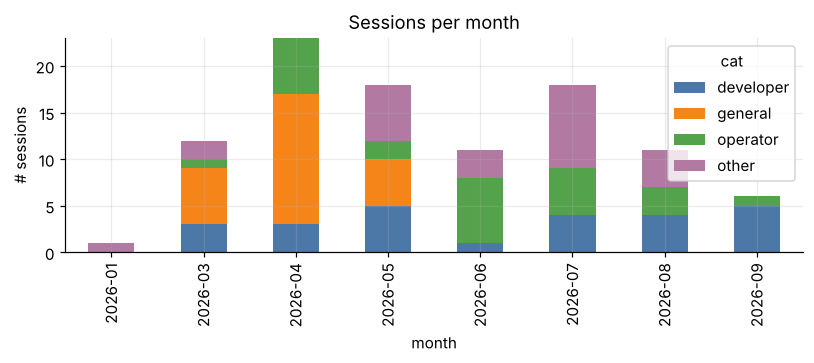

In [22]:
mo = S.assign(month=S.created_at.dt.to_period("M").astype(str)).groupby(["month", "cat"]).size().unstack(fill_value=0)
display(mo)
ax = mo.plot(kind="bar", stacked=True, color=[CAT_COLORS[c] for c in mo.columns], figsize=(7.5, 3.4))
ax.set_ylabel("# sessions"); ax.set_title("Sessions per month"); plt.tight_layout(); plt.show()

# Part C - Findings, gaps and plan

## C1. Key findings in one table

| # | Finding | Evidence | Why it matters for Metis |
|---|---|---|---|
| 1 | Model is constant within each session and bot-specific | 0/87 sessions switch model or system prompt | No per-query routing ground truth exists |
| 2 | 84% of LLM answers already come from cheap models | 318 cheap vs 59 strong (assumed tiers) | Gains vs *current* routing are small; define the baseline explicitly |
| 3 | "Strong" usage is not tied to hard questions | Sonnet: median 36 chars; o3-mini: 8 chars | Don't imitate the logged model choice |
| 4 | Traffic is short, Persian, chatty | 34% <=15 chars, 93% Persian, ~13% greetings | A tiny/fast classifier suffices; Persian handling is mandatory |
| 5 | No code, few attachments, some RAG | 0 code, 14 attachments (images), 71 RAG msgs | Code/multimodal features are low-value in this sample; RAG/system prompt are high-value context |
| 6 | System prompt dominates input cost | ~59% of input tokens; input:output ~10:1 | Cache key and cost model must include it; prompt caching is a lever |
| 7 | Exact repeats ~12%, semantic repeats low | 57 repeats (mostly greetings); non-trivial same-bot ~6% @0.80 | Expect single-digit cache hit rate; cache needs bot namespace + validation |
| 8 | Lexical lookalikes often have different answers | answer-sim median ~0.5 on 17 pairs | Cache thresholds must be tuned on answer equivalence |
| 9 | Data has no cost, token, error, or feedback fields | schema check | Cost, failover and "unsatisfactory answer" must be simulated/derived |
| 10 | Categories are confounded with bots and months | e.g. `general` only Mar-May, `operator` mostly Jun-Sep | Split by session/bot; test leave-one-category-out |
| 11 | Reference answers are imperfect | 3 garbled, 22 JSON, 27 unknown-source | Use an LLM-judge as primary quality metric |

## C2. Gap analysis: what the data gives per Metis requirement

| Metis requirement | What the sample provides | What is missing | How to close the gap |
|---|---|---|---|
| **Feature extraction** (language, intent, code, attachments) | Language, length, intent cues, attachment flag, RAG flag | Code and audio cases (none); Persian slang/typo robustness | Write rules + embeddings; add synthetic code/multimodal tests |
| **Router training labels** | Logged model (confounded) | A "minimum sufficient tier" per prompt | Replay prompts through 2-3 tiers and label with an LLM-judge |
| **Cheap classifier constraint** | Message text | Latency budget & measurement | Benchmark classifier p95 (target a few ms CPU) |
| **Semantic cache** | Raw questions + answers + bot ids | Embeddings; validity labels | Embed with a multilingual model; tune on answer equivalence; namespace by bot |
| **Cascade / escalation** | JSON-validity and retry prompts as natural signals | "Unsatisfactory" label; user feedback (absent) | Validators + refusal/length heuristics + judge score; measure precision/recall |
| **Provider failover** | Nothing (no errors/timeouts logged) | Everything | Fault-injection simulation with a fallback map |
| **Cost vs premium baseline** | Char counts, models, RAG sizes | Token counts, prices | Real tokenizers + verified price table |
| **Latency vs baseline** | 1-s timestamp gaps | Per-model latency distributions | Measure p50/p95 per model with real calls |
| **Quality (similarity / judge)** | 377 reference answers | Reliable references; judge protocol | Pairwise LLM-judge + embedding similarity as secondary |
| **Dashboard (optional)** | - | Logs of routing decisions | Generate from the simulation logs |

## C3. What must be done *before* building (pre-work checklist)

**P0 - Decide the rules of the game (30 min, no code)**
1. Define the *baseline(s)*: (a) always-one-premium-model, (b) the current production mix. Report both.
2. Define the quality floor (e.g. "routed answer judged at least as good as the strong model in >= 95% of cases").
3. Decide which categories/bots are in scope; keep the 4 categories hidden from the model (generalisation requirement).

**P1 - Clean and normalise**
* Drop/handle: workflow answers (36), unknown-source (27), image-model (2); strip `<==...==>` tags; parse JSON answers; mask PII placeholders.
* Persian text normalisation: unify ya/kaf, strip diacritics, handle ZWNJ and Persian/Arabic digits (the `norm()` function above is a starting point).
* Pair each user message with the bot reply that follows it; handle 31 unanswered and 5 repeated user messages.

**P2 - Build the replay set (the backbone of all evaluation)**
One row per LLM turn: `system_prompt, history, retrieved_context, user_message, reference_answer, original_model`. 377 rows today; the full dataset will reuse the same pipeline.

**P3 - Ingredients**
* A verified price table + tokenizers for the candidate models; a candidate pool (e.g. 2 cheap, 1 mid, 1 strong from different providers for failover).
* A multilingual embedding model that handles Persian (verify on a handful of Persian paraphrase pairs first).
* API access and a small budget for labelling/judging (roughly 377 prompts x 3 models + judge calls).

**P4 - Evaluation protocol**
* Split by **session and bot**, never by message; run **leave-one-category-out** as the generalisation test.
* Report cost-quality **curves** (routing share vs quality), not a single accuracy number.

## C4. Advanced analyses that still need to be done (not done in this notebook)

These are the "heavier" EDA / modelling steps that this notebook deliberately skips. They are listed in priority order.

| Priority | Analysis | Why | Output |
|---|---|---|---|
| 1 | **Embed all user messages** (multilingual model), cluster them (UMAP/HDBSCAN or k-means), inspect clusters | Discover real intent groups beyond my rules; basis for router features | Cluster map + per-cluster stats |
| 2 | **Difficulty labelling by replay + LLM-judge**: run each prompt on cheap/mid/strong, judge pairwise, derive "cheapest sufficient tier" | Creates the missing labels; tells how much traffic *can* go cheap | Label table + share per tier by cluster/category |
| 3 | **Router baseline with grouped CV** (logistic regression / gradient boosting on TF-IDF + length + lang + embedding), leave-one-category-out | Shows what is learnable and whether it generalises | Cost-quality curve; feature importance |
| 4 | **Semantic-cache study with embeddings**: hit rate vs threshold, validated by answer equivalence, per bot namespace | Replaces my lexical floor with a real number | Hit-rate / false-hit curve |
| 5 | **Cascade study**: define escalation signals (invalid JSON, refusal, empty/short, low judge score, self-consistency) and measure precision/recall vs judged failures | Quantifies cost/latency overhead of escalation | Escalation rate; added cost |
| 6 | **Metric validation**: correlation between embedding similarity to reference and judge score | Tells whether the similarity metric in the brief is trustworthy | Correlation + calibrated threshold |
| 7 | **Context dependence**: do short follow-ups ("continue", "yes") need conversation history to be classified? | Decides whether the router sees only the last message or a window | Accuracy with/without history |
| 8 | **Real token + price simulation** with sensitivity (price changes, cache rate) and prompt-caching what-if | Produces the publishable savings figure | Cost table per category |
| 9 | **Latency measurement** of candidate models and of the classifier itself | Needed for the "no significant added latency" constraint | p50/p95 table |
| 10 | **Failover fault-injection simulation** | No outage data exists | Availability under simulated outages |
| 11 | **Robustness checks**: Persian slang/typos, mixed languages, abusive text, very long pastes | Real traffic contains all of them | Failure list + rules |

## C5. Recommended path (final suggestion)

**Phase 1 - Foundation (do first):** P0-P3 above; produce the clean replay set and price table.
**Phase 2 - Labels:** analyses #1 and #2. Do not start training anything before this.
**Phase 3 - Router v1:** a layered design, cheapest first:
1. *Hard rules* (zero cost): image/audio attachment -> multimodal-capable model; structured/JSON tasks -> cheap model with validator; greetings/short chat -> cheap model (or cache).
2. *Learned classifier* on embeddings + simple features, trained on the judged labels, outputting P(cheap is enough). Route to cheap when above a threshold chosen from the cost-quality curve.
3. *Safety net* = cascade (Phase 4), so a wrong "cheap" decision costs one extra call, not a bad answer.

**Phase 4 - Cache + cascade + failover:** exact-match cache first (free, ~12% of messages repeat), semantic cache second with a **bot/system-prompt namespace** and a threshold tuned on answer equivalence; escalation on validator/judge signals; failover via a provider fallback map, evaluated by simulation.
**Phase 5 - Evaluation & (optional) dashboard:** report all four brief metrics against **both** baselines; build the dashboard from the simulation logs (tokens saved, cost reduction, cache hits, latency).

**Expectations to set honestly:**
* On this traffic, expect a **single-digit semantic-cache hit rate** (greetings aside) and savings dominated by the routing share and the price ratio.
* Against the *current* production mix (84% already cheap) the incremental gain is modest; against an "always premium" baseline it is large. Present both.
* Don't tune to the four categories; generalisation across them is an explicit requirement.

# Part D - Hand-off prompt for the next assistant

Copy everything inside the block into a new chat (attach this notebook or paste its findings table if the file cannot be attached).

```
I'm working on a project: an LLM routing middleware ("Metis-Auto", a virtual meta-model) that routes each user query to a cheap/fast or a strong/expensive LLM, with a semantic cache, cascade escalation and provider failover. Evaluation metrics from the brief: (1) quality = semantic similarity / LLM-as-judge between routed answer and the actual bot answer, (2) semantic-cache hit rate, (3) simulated cost vs a single premium-model baseline, (4) latency vs baseline.

I already did a basic EDA (summary below). I'm a beginner, so work step by step, give runnable Python (pandas, scikit-learn, sentence-transformers or API embeddings), explain every result in plain language, and ask me before any step that costs money (API calls).

DATA: 100 anonymised sessions, 907 messages (465 user, 442 bot), Jan-Sep 2026, 4 unnamed usage categories x 25 sessions. ~93% Persian.
KEY FINDINGS:
- 377 bot answers are from 16 LLMs; 36 are rule-based workflow answers, 27 have no model recorded, 2 are image-model answers (exclude these).
- Model and system prompt are constant within every session -> the logged model reflects bot config, not query difficulty. There is NO per-message ground-truth routing label. Assumed strong tier = claude-sonnet-4-6, gpt-5.2, gpt-5.4, o3-mini, gpt-4.1, deepseek-reasoner; 84% of LLM answers are already on cheap models. Sonnet answered messages with a median of 36 chars, so "strong" does not mean "hard".
- 34% of user messages are <=15 chars, ~13% greetings/thanks, only 4% >500 chars; no code; 14 attachments (images); 71 bot answers use RAG.
- ~59% of estimated input tokens are the system prompt; input:output ~10:1.
- 12% of user messages are exact repeats (mostly greetings). A lexical (char-TF-IDF) lookalike search finds only ~6% non-trivial near-duplicates at similarity >=0.80 within the same bot; these are mostly templated prompts whose answers differ (median answer similarity ~0.5).
- Reference answers are imperfect (22 JSON, 3 garbled, from heterogeneous models).
- The dataset has no token counts, prices, errors or user feedback.

WHAT I WANT YOU TO DO (in this order, one step per message, wait for my confirmation):
1. Help me build the clean "replay set" (system prompt, history, RAG context, user message, reference answer, original model) from data.json and a Persian text normaliser.
2. Embed all user messages with a multilingual embedding model suitable for Persian, cluster them, and help me interpret the clusters.
3. Design and run a difficulty-labelling experiment: replay each prompt on 2-3 tiers of models, use a pairwise LLM-judge (control position bias, report agreement) to get the "cheapest sufficient tier" label. Estimate the API cost first.
4. Train a small, fast router (logistic regression or gradient boosting on embeddings + simple features) with GROUP cross-validation by session/bot and leave-one-category-out; report cost-quality curves, not just accuracy.
5. Study the semantic cache with embeddings: hit rate vs threshold, validated by answer equivalence, with a cache namespace per system prompt.
6. Study cascade escalation signals (invalid JSON, refusal, very short answers, low judge score) and their precision/recall and extra cost.
7. Build a cost and latency simulator using real tokenizers and a price table I will verify, with a sensitivity analysis and both baselines (always-premium and current mix).
8. Add a failover fault-injection simulation, then (optional) a simple dashboard.
At each step list assumptions, pitfalls with this small dataset, and what to report in my final write-up.
```